# เติมยุคของแหล่งซากดึกดำบรรพ์ (`PERIODFROM`) จาก PBDB

แหล่งซากดึกดำบรรพ์ของกรมทรัพยากรธรณี (518 แหล่ง) มี `PERIODFROM` ว่างอยู่ราว 68%
notebook นี้ใช้ข้อมูล Paleobiology Database ของไทย (`data/pbdb_thailand/`) มาเติม 2 ทาง

| แหล่งข้อมูล | วิธี | สิ่งที่ได้ |
|---|---|---|
| **PBDB taxon** | ชื่อสกุลละตินในคำบรรยายแหล่ง (`FOS_DES_TH`) → ช่วงอายุของสกุลนั้นจาก occurrence ในไทยใน PBDB | อายุของ**ซาก**โดยตรง |
| **PBDB nearby** | collection ของ PBDB ที่ใกล้แหล่งที่สุดในรัศมีที่กำหนด → อายุของ collection (`max_ma`, `min_ma`) | อายุของซากที่ขุดได้ในบริเวณเดียวกัน |

**ตรวจความแม่น**: ใช้ 166 แหล่งที่มี `PERIODFROM` อยู่แล้ว ทำนายด้วยแต่ละวิธีแล้วเทียบกับค่าที่บันทึกไว้
ใช้ผลนี้เลือกรัศมีและจัดระดับความเชื่อมั่น

ผลลัพธ์จะไม่แก้ `PERIODFROM` เดิม แต่เพิ่มคอลัมน์ใหม่ `PERIODFROM_filled` พร้อมบอกแหล่งที่มาและระดับความเชื่อมั่น

In [1]:
import re
import unicodedata
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

DATA = Path("../data")
OUT = DATA / "processed"
OUT.mkdir(exist_ok=True)

_installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONT = next((f for f in ["Tahoma", "Thonburi", "Noto Sans Thai", "Leelawadee UI", "Loma", "Garuda"] if f in _installed), None)
plt.rcParams.update({
    "font.family": [THAI_FONT, "DejaVu Sans"] if THAI_FONT else ["DejaVu Sans"], "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 40, "display.max_colwidth", 60, "display.width", 160)
INK, MUTED = "#52514e", "#8a8984"
SOURCE_COLOR = {"DMR record": "#2a78d6", "PBDB taxon": "#eb6834", "PBDB nearby": "#1baf7a", "missing": "#cfcec9"}

## 1. ยุคทางธรณีวิทยา

ใช้ขอบเขตยุคตาม ICS Chart (ล้านปี) แปลงอายุตัวเลขของ PBDB เป็นชื่อยุค
`max_ma` (อายุเก่าสุด) → ยุคเริ่ม, `min_ma` (อายุอ่อนสุด) → ยุคสิ้นสุด
ส่วน `PERIODFROM` ภาษาไทยที่สะกดหลายแบบ ใช้ regex จับคำสำคัญเหมือนใน notebook 01

In [2]:
# (ชื่อยุค, อายุฐาน Ma, อายุยอด Ma) เรียงจากเก่าไปอ่อน
PERIODS = [("Precambrian", 4600, 538.8), ("Cambrian", 538.8, 485.4), ("Ordovician", 485.4, 443.8),
           ("Silurian", 443.8, 419.2), ("Devonian", 419.2, 358.9), ("Carboniferous", 358.9, 298.9),
           ("Permian", 298.9, 251.902), ("Triassic", 251.902, 201.4), ("Jurassic", 201.4, 143.1),
           ("Cretaceous", 143.1, 66.0), ("Tertiary", 66.0, 2.58), ("Quaternary", 2.58, 0.0)]
ORDER = [p for p, _, _ in PERIODS]
RANK = {p: i for i, p in enumerate(ORDER)}
TH_NAME = {"Precambrian": "พรีแคมเบรียน", "Cambrian": "แคมเบรียน", "Ordovician": "ออร์โดวิเชียน", "Silurian": "ไซลูเรียน",
           "Devonian": "ดีโวเนียน", "Carboniferous": "คาร์บอนิเฟอรัส", "Permian": "เพอร์เมียน", "Triassic": "ไทรแอสซิก",
           "Jurassic": "จูแรสซิก", "Cretaceous": "ครีเทเชียส", "Tertiary": "เทอร์เชียรี", "Quaternary": "ควอเทอร์นารี"}
PERIOD_TH = {
    "Cambrian": r"แคมเบรียน", "Ordovician": r"ออร์โด", "Silurian": r"ไซลูเรียน", "Devonian": r"ดีโวเนียน",
    "Carboniferous": r"คาร์บอนิเฟอรัส", "Permian": r"เพอร์เมียน", "Triassic": r"ไทรแอส", "Jurassic": r"จู(?:แร|รา)ส",
    "Cretaceous": r"ครีเท", "Tertiary": r"เทอร์เชียรี|นีโอจีน|พาลีโอจีน|ไมโอซีน|ไพลโอซีน|โอลิโกซีน|อีโอซีน",
    "Quaternary": r"ควอเทอร์นารี|ไพลสโตซีน|โฮโลซีน",
}


def period_at(ma, side):
    # side='old': อายุ ma เป็นขอบล่างของช่วง (ยอมให้อยู่ที่ฐานยุคพอดี), side='young': ขอบบน
    for p, base, top in PERIODS:
        if (side == "old" and top < ma <= base) or (side == "young" and top <= ma < base):
            return p
    return None


def parse_period_th(text):
    # คืน (ยุคเก่าสุด, ยุคอ่อนสุด) จากข้อความไทยอิสระ
    if not isinstance(text, str):
        return (None, None)
    found = sorted((p for p, pat in PERIOD_TH.items() if re.search(pat, text)), key=RANK.get)
    return (found[0], found[-1]) if found else (None, None)


def overlaps(a_old, a_young, b_old, b_young):
    return RANK[a_old] <= RANK[b_young] and RANK[b_old] <= RANK[a_young]


def th_label(old, young):
    if not isinstance(old, str):
        return None
    return TH_NAME[old] if old == young else f"{TH_NAME[old]}ถึง{TH_NAME[young]}"


def clean_th(s):
    if not isinstance(s, str):
        return s
    s = unicodedata.normalize("NFC", s).replace("ํา", "ำ")
    return re.sub(r"\s+", " ", s).strip()

## 2. โหลดข้อมูล

In [3]:
sites = gpd.read_file(DATA / "dmr_fossil_sites" / "fossil_sites.geojson")
for c in ["NAME_TH", "PROVINCE", "PERIODFROM", "FOS_DES_TH", "FORMATION"]:
    sites[c] = sites[c].map(clean_th).replace({"": None})
sites["OBJECTID"] = sites.OBJECTID.astype(int)
sites[["rec_old", "rec_young"]] = sites.PERIODFROM.map(parse_period_th).tolist()
sites_m = sites.to_crs(32647)

colls = pd.read_csv(DATA / "pbdb_thailand" / "collections.csv", low_memory=False)
occs = pd.read_csv(DATA / "pbdb_thailand" / "occurrences.csv", low_memory=False)
for df in (colls, occs):
    df["p_old"] = df.max_ma.map(lambda a: period_at(a, "old"))
    df["p_young"] = df.min_ma.map(lambda a: period_at(a, "young"))

known = sites.rec_old.notna()
print("collection ที่แปลงอายุเป็นยุคไม่ได้:", colls.p_old.isna().sum(), "| occurrence:", occs.p_old.isna().sum())
print(f"แหล่ง {len(sites)} | มี PERIODFROM {known.sum()} | ว่าง {(~known).sum()} ({(~known).mean():.0%})")
print(f"PBDB: collection {len(colls)} | occurrence {len(occs):,}")

collection ที่แปลงอายุเป็นยุคไม่ได้: 0 | occurrence: 0
แหล่ง 518 | มี PERIODFROM 166 | ว่าง 352 (68%)
PBDB: collection 713 | occurrence 4,965


### คุณภาพพิกัดของ PBDB

collection ของ PBDB ระบุความแม่นของพิกัดไว้ (`latlng_basis`, `latlng_precision`, `geogscale`)
ตัดตัวที่หยาบเกินกว่าจะใช้เทียบระยะไม่กี่กิโลเมตรออก ได้แก่ ตำแหน่งที่อิงเขตการปกครอง (`based on political unit`),
ทศนิยม 0–1 ตำแหน่ง (หยาบกว่า ~11 กม.), ขนาดระดับแอ่ง (`basin`)
และพิกัดที่ตกนอกประเทศไทย (พบ 2 จุด เช่น "Thai Ban" สมุทรปราการ ที่พิกัดไปอยู่ยุโรปเหนือ)

In [4]:
display(pd.crosstab(colls.latlng_basis.fillna("(ว่าง)"), colls.latlng_precision.astype(str)))
outside_th = ~(colls.lng.between(97.3, 105.7) & colls.lat.between(5.6, 20.5))
display(colls.loc[outside_th, ["collection_no", "collection_name", "state", "lng", "lat"]])
coarse = (colls.latlng_basis.eq("based on political unit") | colls.latlng_precision.astype(str).isin(["0", "1"])
          | colls.geogscale.eq("basin") | outside_th)
cg = gpd.GeoDataFrame(colls[~coarse], geometry=gpd.points_from_xy(colls.loc[~coarse, "lng"], colls.loc[~coarse, "lat"]), crs=4326).to_crs(32647)
print(f"ใช้ได้ {len(cg)} จาก {len(colls)} collection (ตัด {coarse.sum()})")

latlng_precision,1,2,3,4,5,6,degrees,minutes,seconds
latlng_basis,,,,,,,,,
(ว่าง),0,1,1,0,0,0,0,1,26
based on nearby landmark,1,18,55,13,4,8,1,73,50
based on political unit,0,1,6,1,0,0,0,3,0
estimated from map,9,45,61,10,2,23,0,54,88
stated in text,0,1,2,1,0,0,0,11,143


,collection_no,collection_name,state,lng,lat
171,78916,Mahang and Baling Fm (Dacryoconarida),Penang,101.040001,5.560000
332,122673,Thai Ban,Samut Prakan,12.453611,66.162224
573,190037,Ban Suan,Chon Buri,101.351997,46.115002


ใช้ได้ 673 จาก 713 collection (ตัด 40)


## 3. วิธี PBDB nearby: collection ที่ใกล้ที่สุด

หา collection ที่ใกล้แหล่งที่สุด แล้วไล่รัศมีสูงสุดที่ยอมรับ ดูว่าเติมได้กี่แหล่งและตรงกับยุคที่บันทึกไว้แค่ไหน
นับว่า "ตรง" เมื่อช่วงยุคของทั้งสองซ้อนทับกัน

,radius_km,validated,accuracy,fills_missing
0,0.500000,8,88%,12
1,1.000000,20,90%,21
2,2.000000,35,89%,63
3,3.000000,44,86%,88
4,5.000000,58,86%,129
5,7.500000,73,85%,160
6,10.000000,83,81%,187
7,15.000000,102,77%,229
8,20.000000,112,76%,264
9,30.000000,136,75%,294


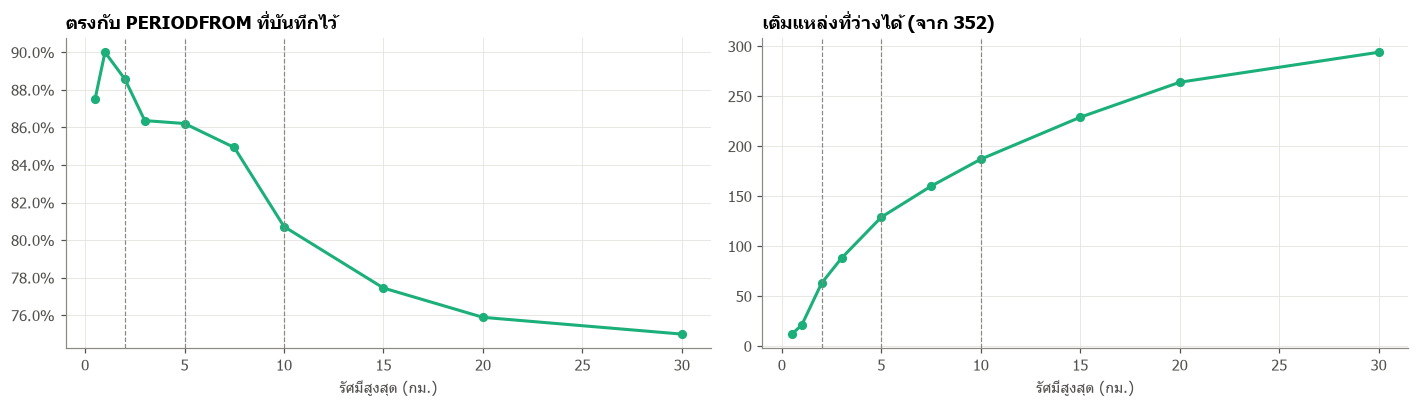

In [5]:
near = gpd.sjoin_nearest(sites_m[["OBJECTID", "geometry"]], cg[["collection_no", "collection_name", "early_interval", "late_interval",
                                                               "max_ma", "min_ma", "p_old", "p_young", "formation", "geometry"]],
                         distance_col="dist_m").drop_duplicates("OBJECTID").drop(columns=["index_right", "geometry"])
near["dist_km"] = near.dist_m / 1000
near = near.merge(sites[["OBJECTID", "rec_old", "rec_young"]], on="OBJECTID")

# ความเห็นตรงกันของ collection อื่นในรัศมีเดียวกัน (บอกว่าบริเวณนั้นมีหลายยุคปนกันไหม)
def consensus(row, radius_km):
    d = cg.distance(sites_m.set_index("OBJECTID").geometry[row.OBJECTID]) / 1000
    nb = cg[d <= max(radius_km, row.dist_km)]
    agree = [overlaps(row.p_old, row.p_young, o, y) for o, y in zip(nb.p_old, nb.p_young) if isinstance(o, str) and isinstance(y, str)]
    return len(nb), float(np.mean(agree))


near[["n_colls_in_radius", "consensus"]] = [consensus(r, 2) for r in near.itertuples()]
near["agree"] = [overlaps(a, b, c, d) if isinstance(a, str) and isinstance(c, str) else np.nan for a, b, c, d in zip(near.rec_old, near.rec_young, near.p_old, near.p_young)]

radii = [0.5, 1, 2, 3, 5, 7.5, 10, 15, 20, 30]
curve = pd.DataFrame([{
    "radius_km": r,
    "validated": (near.dist_km.le(r) & near.rec_old.notna()).sum(),
    "accuracy": near.loc[near.dist_km.le(r) & near.rec_old.notna(), "agree"].mean(),
    "fills_missing": (near.dist_km.le(r) & near.rec_old.isna()).sum(),
} for r in radii])
display(curve.style.format({"accuracy": "{:.0%}"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(curve.radius_km, curve.accuracy, color="#1baf7a", lw=2, marker="o", ms=5)
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[0].set_title("ตรงกับ PERIODFROM ที่บันทึกไว้")
axes[1].plot(curve.radius_km, curve.fills_missing, color="#1baf7a", lw=2, marker="o", ms=5)
axes[1].set_title(f"เติมแหล่งที่ว่างได้ (จาก {(~known).sum()})")
for ax in axes:
    ax.set_xlabel("รัศมีสูงสุด (กม.)")
    for r in (2, 5, 10):
        ax.axvline(r, color=MUTED, ls="--", lw=0.8)
plt.tight_layout()

ความแม่นลดลงเรื่อย ๆ เมื่อรัศมีกว้างขึ้น ไทยมีหินหลายยุคอยู่ติดกัน (เช่น หินปูนเพอร์เมียนติดกับหินตะกอนมีโซโซอิก)
จึงกำหนด 3 ระดับความเชื่อมั่นจากเส้นโค้งนี้ และไม่เติมถ้าไกลเกิน 10 กม.
(ตารางด้านล่างคือความแม่น**เฉพาะช่วง**ของแต่ละระดับ ซึ่งต่างจากเส้นโค้งที่เป็นค่าสะสม)

| ระยะ | ความเชื่อมั่น |
|---|---|
| ≤ 2 กม. | high |
| 2–5 กม. | medium |
| 5–10 กม. | low |

In [6]:
TIERS = [(2, "high"), (5, "medium"), (10, "low")]  # (รัศมี กม., ระดับ)


def tier(d):
    return next((name for r, name in TIERS if d <= r), None)


near["confidence"] = near.dist_km.map(tier)
acc_by_tier = near[near.rec_old.notna() & near.confidence.notna()].groupby("confidence").agree.agg(["size", "mean"]).reindex(["high", "medium", "low"])
acc_by_tier.columns = ["ตรวจได้ (แหล่ง)", "ตรงกับที่บันทึก"]
acc_by_tier.style.format({"ตรงกับที่บันทึก": "{:.0%}"})

,ตรวจได้ (แหล่ง),ตรงกับที่บันทึก
confidence,,
high,35,89%
medium,23,83%
low,25,68%


ระดับ `low` (5–10 กม.) ตรงกับที่บันทึกไว้ราวสองในสามเท่านั้น ใช้เป็นค่าประมาณคร่าว ๆ ได้
ถ้างานต้องการความแม่น ให้กรองไว้แค่ `period_confidence` เป็น `recorded`, `high` หรือ `medium`

## 4. วิธี PBDB taxon: ชื่อสกุลในคำบรรยายแหล่ง

ดึงชื่อสกุลละตินจาก `FOS_DES_TH` (เช่น *Siamraptor*, *Linoproductus*) แล้วหาช่วงอายุที่สกุลนั้นพบในไทยจาก occurrence ของ PBDB
ถ้าแหล่งมีหลายสกุล ใช้ช่วงที่ครอบคลุมทุกสกุล และไม่ใช้สกุลที่ช่วงอายุในไทยกว้างเกิน 2 ยุค (บอกอายุได้ไม่ชัด)

In [7]:
NOT_GENUS = {"Rugosa", "Tabulata", "Productid"}
sites["genera"] = sites.FOS_DES_TH.fillna("").str.findall(r"\b([A-Z][a-z]{3,})\b").map(
    lambda L: sorted({g for g in L if not g.endswith(("idae", "oidea"))} - NOT_GENUS))

occs["g"] = occs.genus.fillna(occs.accepted_name.str.split().str[0])
grange = occs.groupby("g").agg(old=("p_old", lambda x: min(x.dropna(), key=RANK.get)),
                               young=("p_young", lambda x: max(x.dropna(), key=RANK.get)), n_occs=("g", "size"))
grange["span"] = grange.young.map(RANK) - grange.old.map(RANK) + 1
diagnostic = grange[grange.span <= 2]

rows = []
for r in sites.itertuples():
    hits = [g for g in r.genera if g in diagnostic.index]
    if hits:
        rows.append({"OBJECTID": r.OBJECTID, "taxa": ", ".join(hits),
                     "t_old": min((diagnostic.at[g, "old"] for g in hits), key=RANK.get),
                     "t_young": max((diagnostic.at[g, "young"] for g in hits), key=RANK.get)})
taxon = pd.DataFrame(rows).merge(sites[["OBJECTID", "NAME_TH", "PERIODFROM", "rec_old", "rec_young"]], on="OBJECTID")
taxon["agree"] = [overlaps(a, b, c, d) if isinstance(a, str) and isinstance(c, str) else np.nan for a, b, c, d in zip(taxon.rec_old, taxon.rec_young, taxon.t_old, taxon.t_young)]
v = taxon[taxon.rec_old.notna()]
print(f"แหล่งที่มีสกุลใน PBDB ไทย: {len(taxon)} | ตรวจได้ {len(v)} ตรง {v.agree.mean():.0%} | เติมแหล่งที่ว่างได้ {taxon.rec_old.isna().sum()}")
v.loc[v.agree.eq(False), ["NAME_TH", "PERIODFROM", "taxa", "t_old", "t_young"]]

แหล่งที่มีสกุลใน PBDB ไทย: 43 | ตรวจได้ 11 ตรง 73% | เติมแหล่งที่ว่างได้ 32


,NAME_TH,PERIODFROM,taxa,t_old,t_young
6,สัตว์มีกระดูกสันหลังถ้ำเพดาน,เพอร์เมียน,Crocuta,Quaternary,Quaternary
10,สัตว์มีกระดูกสันหลังถ้ำยายรวก,เพอร์เมียน,"Crocuta, Rhinoceros",Quaternary,Quaternary
12,สโตรมาโตไลต์ป่าแก่,ออร์โดวิเชียน,"Diplograptus, Monograptus",Silurian,Devonian


กรณีที่ "ไม่ตรง" ส่วนใหญ่เป็น**ถ้ำ** ที่ `PERIODFROM` บันทึกอายุของหินปูนรอบถ้ำ (เพอร์เมียน)
แต่ซากในถ้ำ เช่น ไฮยีนา (*Crocuta*) กับแรด (*Rhinoceros*) เป็นสัตว์ยุคควอเทอร์นารีที่เข้าไปอยู่ในถ้ำทีหลังมาก
แปลว่า `PERIODFROM` ของ ทธ. ปนกันระหว่าง**อายุหิน**กับ**อายุซาก** วิธี taxon ให้อายุซากซึ่งตรงกับความหมายของชุดข้อมูลซากมากกว่า
จึงให้ลำดับความสำคัญสูงกว่าวิธี nearby

## 5. รวมผล

ลำดับการเติม (ใช้ค่าแรกที่มี)
1. **DMR record**: `PERIODFROM` เดิม (ไม่แก้)
2. **PBDB taxon**: ชื่อสกุลในคำบรรยายแหล่ง → confidence `high`
3. **PBDB nearby**: collection ที่ใกล้สุด ≤ 10 กม. → confidence ตามระยะ

ระหว่างทาง ถ้า taxon กับ nearby ขัดกันจะบันทึกไว้ใน `pbdb_conflict`

In [8]:
f = sites[["OBJECTID", "SITE_CODE", "NAME_TH", "PROVINCE", "PERIODFROM", "rec_old", "rec_young", "geometry"]].copy()
f = f.merge(taxon[["OBJECTID", "taxa", "t_old", "t_young"]], on="OBJECTID", how="left")
f = f.merge(near[["OBJECTID", "collection_no", "collection_name", "early_interval", "late_interval", "max_ma", "min_ma",
                  "p_old", "p_young", "dist_km", "n_colls_in_radius", "consensus", "confidence"]], on="OBJECTID", how="left")
use_near = f.confidence.notna()

src = np.select([f.rec_old.notna(), f.t_old.notna(), use_near], ["DMR record", "PBDB taxon", "PBDB nearby"], "missing")
f["period_source"] = src
f["period_old"] = np.select([src == "DMR record", src == "PBDB taxon", src == "PBDB nearby"], [f.rec_old, f.t_old, f.p_old], None)
f["period_young"] = np.select([src == "DMR record", src == "PBDB taxon", src == "PBDB nearby"], [f.rec_young, f.t_young, f.p_young], None)
f["PERIODFROM_filled"] = np.where(src == "DMR record", f.PERIODFROM, [th_label(o, y) for o, y in zip(f.period_old, f.period_young)])
f["period_confidence"] = np.select([src == "DMR record", src == "PBDB taxon", src == "PBDB nearby"], ["recorded", "high", f.confidence], None)
f["pbdb_conflict"] = [bool(t and p and not overlaps(t, ty, p, py)) if (isinstance(t, str) and isinstance(p, str) and d <= 10) else False
                      for t, ty, p, py, d in zip(f.t_old, f.t_young, f.p_old, f.p_young, f.dist_km.fillna(1e9))]

print(f"PERIODFROM ว่าง: ก่อน {(~known).sum()} แหล่ง ({(~known).mean():.0%}) → หลัง {(src == 'missing').sum()} แหล่ง ({(src == 'missing').mean():.0%})")
print(f"taxon กับ nearby ขัดกัน: {f.pbdb_conflict.sum()} แหล่ง")
pd.crosstab(f.period_source, f.period_confidence.fillna("-")).reindex(["DMR record", "PBDB taxon", "PBDB nearby", "missing"])

PERIODFROM ว่าง: ก่อน 352 แหล่ง (68%) → หลัง 159 แหล่ง (31%)
taxon กับ nearby ขัดกัน: 2 แหล่ง


period_confidence,-,high,low,medium,recorded
period_source,,,,,
DMR record,0,0,0,0,166
PBDB taxon,0,32,0,0,0
PBDB nearby,0,45,56,60,0
missing,159,0,0,0,0


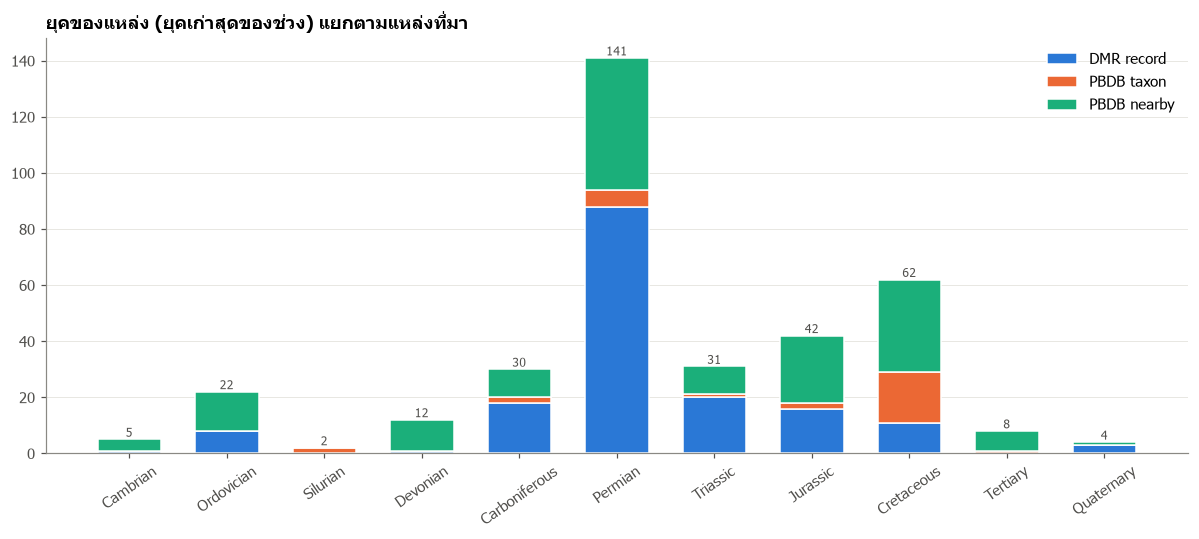

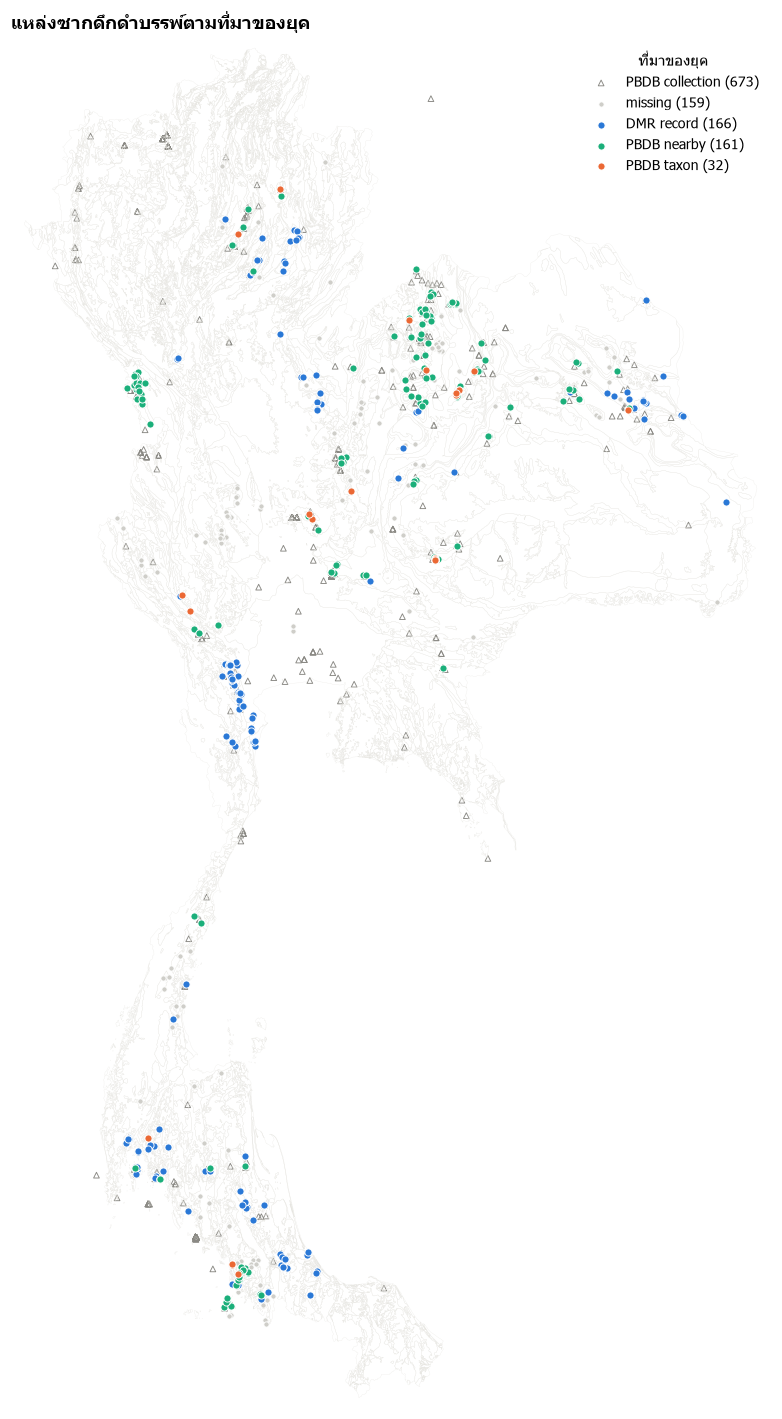

In [9]:
counts = pd.crosstab(f.period_old, f.period_source).reindex([p for p in ORDER if p in set(f.period_old.dropna())])
counts = counts[[c for c in ["DMR record", "PBDB taxon", "PBDB nearby"] if c in counts]]

fig, ax = plt.subplots(figsize=(11, 5))
bottom = np.zeros(len(counts))
for s in counts.columns:
    ax.bar(counts.index, counts[s], bottom=bottom, color=SOURCE_COLOR[s], label=s, width=0.65, edgecolor="white", linewidth=1)
    bottom += counts[s].values
for x, v in enumerate(bottom):
    ax.text(x, v, f"{v:.0f}", ha="center", va="bottom", fontsize=8, color=INK)
ax.set_title("ยุคของแหล่ง (ยุคเก่าสุดของช่วง) แยกตามแหล่งที่มา")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
plt.tight_layout()

rock = gpd.read_file(DATA / "dmr_geology" / "rock_unit_250k.geojson")[["geometry"]]
fig, ax = plt.subplots(figsize=(8, 13))
rock.boundary.plot(ax=ax, color="#e6e5e0", linewidth=0.15)
cg.to_crs(4326).plot(ax=ax, color="none", edgecolor=MUTED, markersize=14, linewidth=0.6, marker="^", label=f"PBDB collection ({len(cg)})")
for s in ["missing", "DMR record", "PBDB nearby", "PBDB taxon"]:
    sub = f[f.period_source.eq(s)]
    gpd.GeoSeries(sub.geometry, crs=4326).plot(ax=ax, color=SOURCE_COLOR[s], markersize=22 if s != "missing" else 12,
                                               edgecolor="white", linewidth=0.6, label=f"{s} ({len(sub)})", zorder=3)
ax.set_xlim(97.2, 105.8)
ax.set_ylim(5.5, 20.6)
ax.set_axis_off()
ax.legend(loc="upper right", frameon=False, fontsize=9, title="ที่มาของยุค")
ax.set_title("แหล่งซากดึกดำบรรพ์ตามที่มาของยุค", loc="left", fontweight="bold")
plt.tight_layout()

## 6. บันทึกผล

- `data/processed/sites_period_filled.geojson` / `.csv`: แหล่งทั้ง 518 แห่ง
  - `PERIODFROM` เดิม (ไม่แก้), `PERIODFROM_filled` (ภาษาไทย), `period_old` / `period_young` (ชื่อยุคมาตรฐาน)
  - `period_source`, `period_confidence`, `pbdb_conflict`
  - หลักฐานจาก PBDB: `taxa`, `collection_no`, `collection_name`, `early_interval`, `late_interval`, `max_ma`, `min_ma`, `dist_km`, `consensus`
  - คำทายของแต่ละวิธีแยกกัน (มีค่าแม้แหล่งนั้นจะมี `PERIODFROM` แล้ว): `taxon_old/young`, `nearby_old/young`, `nearby_confidence`
- `data/processed/fossil_list_merged_with_period.csv`: ผลจาก notebook 02 (`fossil_list_merged.csv`) เพิ่มยุคของแหล่งที่เชื่อมไว้

In [10]:
out_cols = ["OBJECTID", "SITE_CODE", "NAME_TH", "PROVINCE", "PERIODFROM", "PERIODFROM_filled", "period_old", "period_young",
            "period_source", "period_confidence", "pbdb_conflict", "taxa", "collection_no", "collection_name",
            "early_interval", "late_interval", "max_ma", "min_ma", "dist_km", "n_colls_in_radius", "consensus",
            "taxon_old", "taxon_young", "nearby_old", "nearby_young", "nearby_confidence"]
# คำทายของแต่ละวิธีสำหรับทุกแหล่ง (รวมแหล่งที่มี PERIODFROM แล้ว) ไว้ใช้วัดความแม่นตอนรวมผล (notebook 05)
f["taxon_old"], f["taxon_young"] = f.t_old, f.t_young
f["nearby_old"] = f.p_old.where(use_near)
f["nearby_young"] = f.p_young.where(use_near)
f["nearby_confidence"] = f.confidence
res = gpd.GeoDataFrame(f[out_cols + ["geometry"]], geometry="geometry", crs=4326)
res.to_file(OUT / "sites_period_filled.geojson", driver="GeoJSON")
res.drop(columns="geometry").assign(longitude=res.geometry.x, latitude=res.geometry.y).to_csv(
    OUT / "sites_period_filled.csv", index=False, encoding="utf-8-sig")

merged_path = OUT / "fossil_list_merged.csv"
if merged_path.exists():
    m = pd.read_csv(merged_path, dtype={"fossil_id": str, "SITE_CODE": str, "site_SITE_CODE": str, "site_OBJECTID": "Int64"}, encoding="utf-8-sig", low_memory=False)
    add = f[["OBJECTID", "PERIODFROM_filled", "period_old", "period_young", "period_source", "period_confidence"]].rename(
        columns=lambda c: "site_" + c)
    m = m.merge(add, on="site_OBJECTID", how="left")
    m.to_csv(OUT / "fossil_list_merged_with_period.csv", index=False, encoding="utf-8-sig")
    has = m.site_OBJECTID.notna()
    print(f"ตัวอย่างที่เชื่อมแหล่งได้ {has.sum():,} ชิ้น | มียุคของแหล่ง: ก่อน {m.loc[has, 'site_PERIODFROM'].notna().sum():,} → หลัง {m.loc[has, 'site_PERIODFROM_filled'].notna().sum():,}")
else:
    print("ไม่พบ fossil_list_merged.csv (รัน notebook 02 ก่อน) จึงข้ามการเพิ่มยุคให้ตัวอย่าง")

print("บันทึก", OUT / "sites_period_filled.geojson")
res.drop(columns="geometry").query("period_source != 'DMR record'").sort_values(["period_source", "dist_km"]).head(15)

ตัวอย่างที่เชื่อมแหล่งได้ 7,853 ชิ้น | มียุคของแหล่ง: ก่อน 2,283 → หลัง 5,529
บันทึก ../data/processed/sites_period_filled.geojson


,OBJECTID,SITE_CODE,NAME_TH,PROVINCE,PERIODFROM,PERIODFROM_filled,period_old,period_young,period_source,period_confidence,pbdb_conflict,taxa,collection_no,collection_name,early_interval,late_interval,max_ma,min_ma,dist_km,n_colls_in_radius,consensus,taxon_old,taxon_young,nearby_old,nearby_young,nearby_confidence
191,11367,0142014,แบรคิโอพอดวัดถ้ำมโหฬาร,เลย,None,เพอร์เมียน,Permian,Permian,PBDB nearby,high,False,NaN,223959,"08LO07-3, Sak Chai quarry, Loei",Sakmarian,NaN,293.52,290.100,0.030700,17.0,0.941176,NaN,NaN,Permian,Permian,high
180,11356,0519002,ฟิวซูลินิดเขาขาว,สระบุรี,None,เพอร์เมียน,Permian,Permian,PBDB nearby,high,False,NaN,118847,Khao Khao KK-a,Wordian,NaN,266.90,264.280,0.036093,5.0,1.000000,NaN,NaN,Permian,Permian,high
94,11269,0152002,สัตว์ไม่มีกระดูกสันหลังดอยผาพลึง,ลำปาง,None,เพอร์เมียน,Permian,Permian,PBDB nearby,high,False,NaN,128471,"Block A, eastern foot of Khao Doi Pha Phlung",Changhsingian,NaN,254.14,251.902,0.047477,8.0,1.000000,NaN,NaN,Permian,Permian,high
42,11217,0142024,แบรคิโอพอดห้วยหลวง,เลย,None,คาร์บอนิเฟอรัส,Carboniferous,Carboniferous,PBDB nearby,high,False,NaN,133253,"Huai Luang LE-7, Wang Saphung",Moscovian,NaN,315.20,307.000,0.050705,5.0,1.000000,NaN,NaN,Carboniferous,Carboniferous,high
326,11502,0142003,สัตว์ไม่มีกระดูกสันหลังอ่างเก็บน้ำห้วยอีเลิศ,เลย,None,เพอร์เมียน,Permian,Permian,PBDB nearby,high,False,NaN,74978,Huai I-Loet reservoir (Huai Sam Pot),Artinskian,NaN,290.10,283.300,0.063342,13.0,1.000000,NaN,NaN,Permian,Permian,high
265,11441,0167019,สัตว์ไม่มีกระดูกสันหลังบ้านซับสาวโสด,เพชรบูรณ์,None,เพอร์เมียน,Permian,Permian,PBDB nearby,high,False,NaN,117110,"Khlong Khon Kaen, Locality O (860810-02~05)",Wordian,NaN,266.90,264.280,0.139723,6.0,1.000000,NaN,NaN,Permian,Permian,high
97,11272,0127001,ไครนอยด์เขาฉกรรจ์,สระแก้ว,None,เพอร์เมียน,Permian,Permian,PBDB nearby,high,False,NaN,118844,Khao Chakan KB-7,Kungurian,NaN,283.30,274.400,0.171360,2.0,1.000000,NaN,NaN,Permian,Permian,high
466,11642,0167003,ปะการังบ้านโภชน์,เพชรบูรณ์,None,เพอร์เมียน,Permian,Permian,PBDB nearby,high,False,NaN,223965,"07PB06-3, Ban Naen Sawan II, Phetchabun",Roadian,NaN,274.40,266.900,0.194626,9.0,1.000000,NaN,NaN,Permian,Permian,high
308,11484,0167022,สัตว์ไม่มีกระดูกสันหลังบ้านซับรู,เพชรบูรณ์,None,เพอร์เมียน,Permian,Permian,PBDB nearby,high,False,NaN,223965,"07PB06-3, Ban Naen Sawan II, Phetchabun",Roadian,NaN,274.40,266.900,0.204863,9.0,1.000000,NaN,NaN,Permian,Permian,high
222,11398,0240007,แหล่งขุดค้นไดโนเสาร์ภูเวียงหลุมขุดค้นที่ 7 (ภูน้อย),ขอนแก่น,None,จูแรสซิกถึงครีเทเชียส,Jurassic,Cretaceous,PBDB nearby,high,False,NaN,157421,"Phu Noi [Phu Kradung Formation], PNB layer",Tithonian,Berriasian,149.20,137.050,0.352535,3.0,1.000000,NaN,NaN,Jurassic,Cretaceous,high


## 7. ข้อจำกัด

- **`PERIODFROM` ปนอายุหินกับอายุซาก**: แหล่งในถ้ำมักบันทึกอายุหินปูน ส่วน PBDB บันทึกอายุซาก ความ "ไม่ตรง" ส่วนหนึ่งจึงไม่ใช่ความผิดพลาด
- **วิธี nearby สมมติว่าแหล่งใกล้กันมีอายุเดียวกัน**: ใช้ไม่ได้ดีตรงรอยต่อหน่วยหิน ดู `consensus` (สัดส่วน collection ในรัศมีที่ยุคตรงกัน) ประกอบ ถ้าต่ำแปลว่าบริเวณนั้นมีหลายยุคปนกัน
- **ระดับยุคเท่านั้น**: ไม่ได้เติมตอนต้น/กลาง/ปลาย แต่ `early_interval`, `max_ma`, `min_ma` ของ PBDB ให้รายละเอียดละเอียดกว่าไว้ใช้ต่อได้
- **ยังว่างอยู่**: แหล่งที่ไม่มี PBDB ในรัศมี 10 กม. ใช้แผนที่หน่วยหิน 1:250,000 เติมต่อได้ (ทำไว้ใน notebook 01 ส่วนที่ 5) แต่นั่นเป็นอายุหิน ไม่ใช่อายุซาก